# Submissions V03 and V04 (Ludovico)

**Goal:** send the two best pipelines found so far, one per model family.

| | V03 · linear | V04 · tree |
|---|---|---|
| Model | logistic regression | gradient boosting (default settings) |
| Preprocessing | median/mode, signed log, robust scaler, one-hot (min 50) | median/mode, one-hot (min 50) |
| New feature | month of purchase | month of purchase |
| Feature selection | **L1** (`SelectFromModel`, C = 0.05): ~22 of 76 columns | none |
| Source | `preprocessing_ludovico`, `features_ludovico` §5 and §12 | same |

For comparison: V01 (logistic, baseline) CV 0.771 → Kaggle 0.770; V02 (+ preprocessing) CV 0.781 → Kaggle 0.775.

<div class="alert alert-block alert-info">

# TOC<a class="anchor" id="toc"></a>
* [<font color='#E8800A'>Setup</font>](#setup)
* [<font color='#E8800A'>1. The two pipelines</font>](#pipelines)
* [<font color='#E8800A'>2. Expected scores from the validation</font>](#expected)
* [<font color='#E8800A'>3. Fit on all train, predict test, submit</font>](#submit)
* [<font color='#E8800A'>4. Publish and upload</font>](#publish)
* [<font color='#E8800A'>5. Which columns V03 uses</font>](#importance)

</div>

# <font color='#E8800A'>Setup</font> <a class="anchor" id="setup"></a>
[Back to TOC](#toc)

`%run` executes `preprocessing_ludovico.ipynb` (about 2 minutes): clean data, official folds, the two recipes, `evaluate` and `best_threshold`. It does **not** run `features_ludovico.ipynb`, which takes about 10 minutes because of all its experiments. The two pieces needed from it, the month feature and the L1 selector, are restated below exactly as they are defined there.

In [1]:
%%capture
%run ./preprocessing_ludovico.ipynb

In [2]:
from sklearn.feature_selection import SelectFromModel

from src.submissions import check_submission, publish, record_kaggle_score, submission_path, submit

ALWAYS_DROP = ["customer_id", "purchase_date", "random_noise"]
X_full = train.drop(columns=[TARGET])  # identifiers and date are needed to build the month, then dropped
X_test_full = test.copy()

# <font color='#E8800A'>1. The two pipelines</font> <a class="anchor" id="pipelines"></a>
[Back to TOC](#toc)

Same definitions as `features_ludovico`:
- `add_month`: the `calendar` group (month of purchase as a categorical column), then the identifiers are dropped.
- `signed_log1p`: the numeric transform of the linear recipe, equal to `log1p` on non-negative columns.
- L1 selector: L1 logistic regression on standardised columns, `C = 0.05`. Columns with a non-zero coefficient are kept. It is refitted on whatever rows the pipeline is trained on.

In [3]:
def add_month(df):
    """The `calendar` feature group of features_ludovico, then drop the identifiers."""
    df = df.assign(purchase_month=df["purchase_date"].dt.month.astype(str))
    return df.drop(columns=[c for c in ALWAYS_DROP if c in df.columns])


def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


l1_selector = SelectFromModel(
    make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver="saga", C=0.05, max_iter=5000)),
    importance_getter="named_steps.logisticregression.coef_",
)


def v03_pipeline():
    """Logistic regression: month -> linear recipe -> L1 selection -> model."""
    steps = linear_recipe(LogisticRegression(max_iter=2000)).set_params(
        prep__num__transform=FunctionTransformer(signed_log1p, feature_names_out="one-to-one")).steps
    return Pipeline([("features", FunctionTransformer(add_month)), *steps[:-1],
                     ("select", clone(l1_selector)), steps[-1]])


def v04_pipeline():
    """Gradient boosting: month -> tree recipe -> model (no selection)."""
    steps = tree_recipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)).steps
    return Pipeline([("features", FunctionTransformer(add_month)), *steps])


PIPELINES = {"V03 logistic + L1": v03_pipeline, "V04 gradient boosting": v04_pipeline}

# <font color='#E8800A'>2. Expected scores from the validation</font> <a class="anchor" id="expected"></a>
[Back to TOC](#toc)

Same rules as for V01 and V02, on the **official folds**:
- **final threshold:** best F1 on the out-of-fold predictions of all folds;
- **honest F1:** threshold chosen on folds 1–2, scored on fold 3. This is the number to compare with Kaggle.

The numbers must match `features_ludovico` §12 (0.796 / 0.802 and 0.774 / 0.777). The assertion checks that the restated pipelines are the same ones.

In [4]:
early = np.concatenate([va for _, va in official_folds[:-1]])
last = official_folds[-1][1]

expected = {}
for name, make in PIPELINES.items():
    scores, oof = evaluate(make(), official_folds, X_full, y)
    covered = oof.notna()
    threshold, _ = best_threshold(y[covered], oof[covered])
    t_early, _ = best_threshold(y.iloc[early], oof.iloc[early])
    expected[name] = {"ROC AUC": scores["ROC AUC"].mean(), "final threshold": threshold,
                      "threshold folds 1-2": t_early,
                      "honest F1 (fold 3)": f1_score(y.iloc[last], oof.iloc[last] >= t_early)}
expected = pd.DataFrame(expected).T

assert abs(expected.loc["V03 logistic + L1", "ROC AUC"] - 0.7958) < 5e-4
assert abs(expected.loc["V04 gradient boosting", "ROC AUC"] - 0.7742) < 5e-4
expected.style.format("{:.3f}").format("{:.2f}", subset=["final threshold", "threshold folds 1-2"])

,ROC AUC,final threshold,threshold folds 1-2,honest F1 (fold 3)
V03 logistic + L1,0.796,0.43,0.43,0.802
V04 gradient boosting,0.774,0.35,0.26,0.777


# <font color='#E8800A'>3. Fit on all train, predict test, submit</font> <a class="anchor" id="submit"></a>
[Back to TOC](#toc)

Each pipeline is refitted on **all** clean train rows (the L1 selector picks its columns again on all of them), predicts test, and the final threshold turns probabilities into 0/1. `submit` assigns the next free version numbers (V03 and V04) and logs them.

In [5]:
predictions = {}
for name, make in PIPELINES.items():
    final_model = make().fit(X_full, y)
    proba = final_model.predict_proba(X_test_full)[:, 1]
    predictions[name] = pd.DataFrame({"ID": test.index, TARGET: (proba >= expected.loc[name, "final threshold"]).astype(int)})
    check_submission(predictions[name])
    if name.startswith("V03"):
        kept = final_model.named_steps["select"].get_support()
        names = final_model.named_steps["prep"].get_feature_names_out()
        print(f"L1 kept {kept.sum()} of {len(kept)} columns on all train:", ", ".join(n.split("__")[-1] for n in names[kept]))

v02 = pd.read_csv(submission_path(2))
pd.DataFrame({name: {"share of 1s": p[TARGET].mean(),
                     "same label as V02": (p[TARGET].to_numpy() == v02[TARGET].to_numpy()).mean()}
              for name, p in predictions.items()}).T.style.format("{:.3f}")

L1 kept 25 of 84 columns on all train: total_tax, discount_line, cost, prior_max_purchase_value, prior_mean_gap_days, prior_std_gap_days, spend_30d, purchase_count_90d, purchase_count_365d, payment_type_Maybe Tomorrow Payment 9, salesperson_VLOOKUP Master 4, transport_method_Maybe Tomorrow Delivery 11, transport_method_Maybe Tomorrow Delivery 22, transport_method_Maybe Tomorrow Delivery 51, transport_method_Maybe Tomorrow Delivery 68, transport_method_Maybe Tomorrow Delivery 80, purchase_month_1, purchase_month_10, purchase_month_11, purchase_month_12, purchase_month_3, purchase_month_4, purchase_month_5, purchase_month_8, purchase_month_9


,share of 1s,same label as V02
V03 logistic + L1,0.736,0.904
V04 gradient boosting,0.783,0.881


In [6]:
versions = {}
for name, notes_model in [
    ("V03 logistic + L1", "logistic regression + linear recipe + month + L1 selection (C=0.05)"),
    ("V04 gradient boosting", "gradient boosting (default) + tree recipe + month, no selection"),
]:
    row = expected.loc[name]
    versions[name] = submit(
        predictions[name],
        notebook="submission_v03_v04_ludovico",
        model=notes_model,
        cv_f1=row["honest F1 (fold 3)"],
        notes=(f"threshold {row['final threshold']:.2f} from time CV + gap; CV ROC AUC {row['ROC AUC']:.3f}; "
               f"{predictions[name][TARGET].mean():.0%} predicted 1"),
    )
versions

V03 saved as submissions/ML_Group_41_Version03.csv and logged:
  Version: 03 | Date: 2026-10-15 | Author: Ludovico Piras | Notebook / model: submission_v03_v04_ludovico · logistic regression + linear recipe + month + L1 selection (C=0.05) | CV F1: 0.802 | Notes: threshold 0.43 from time CV + gap; CV ROC AUC 0.796; 74% predicted 1
Next: publish(3) to reserve the version, then upload the file on Kaggle.


V04 saved as submissions/ML_Group_41_Version04.csv and logged:
  Version: 04 | Date: 2026-10-15 | Author: Ludovico Piras | Notebook / model: submission_v03_v04_ludovico · gradient boosting (default) + tree recipe + month, no selection | CV F1: 0.777 | Notes: threshold 0.35 from time CV + gap; CV ROC AUC 0.774; 78% predicted 1
Next: publish(4) to reserve the version, then upload the file on Kaggle.


{'V03 logistic + L1': 3, 'V04 gradient boosting': 4}

# <font color='#E8800A'>4. Publish and upload</font> <a class="anchor" id="publish"></a>
[Back to TOC](#toc)

**Reserve both versions on GitHub** (commit + push of the two CSVs and the log only), **then** upload the printed files on Kaggle:

In [ ]:
versions = {name: publish(version) for name, version in versions.items()}

After the uploads, record the two public scores and share them:

In [ ]:
# record_kaggle_score(versions["V03 logistic + L1"], 0.0)      # <- public score of V03
# record_kaggle_score(versions["V04 gradient boosting"], 0.0)  # <- public score of V04
# publish(versions["V04 gradient boosting"])                  # one publish shares the log with both scores

### How to read the results
- **V03 near its honest estimate (≈ 0.80)** → preprocessing + month + L1 transfer to Kaggle. Compare with V02 (0.775): the expected gain is about +0.02.
- **V04 vs V03:** in validation the tuned-free boosting is below the logistic regression (0.777 vs 0.802). If Kaggle agrees, it supports keeping linear models among the candidates of `06_models` and tuning the boosting before relying on it.
- The public leaderboard is noisy (±0.02–0.03). Read differences under ~0.02 as ties.

# <font color='#E8800A'>5. Which columns V03 uses</font> <a class="anchor" id="importance"></a>
[Back to TOC](#toc)

- **Coefficients:** the columns kept by L1 on all train and their weight in the final model (orange = higher probability of buying again). Numeric and one-hot coefficients are on different scales: compare signs and rough order, not exact sizes.
- **Permutation importance:** for each official fold, one raw column of the validation block is shuffled and the drop in ROC AUC is measured. Needs setup and section 1; about 1 minute.
- `auc_drops` is not called `drops`: that name is used by `preprocessing_ludovico` and overwriting it breaks `v03_pipeline()`.

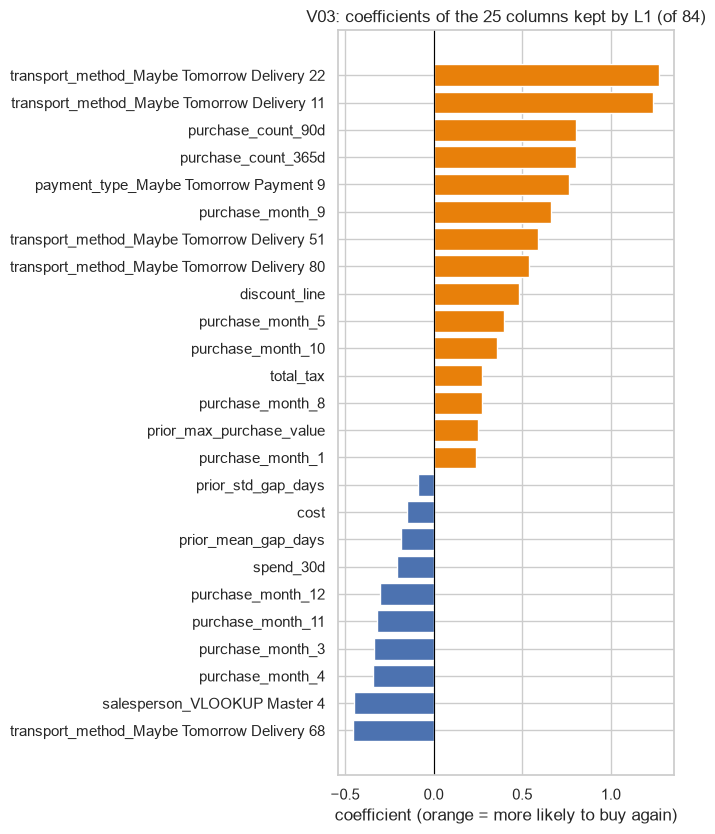

In [4]:
import matplotlib.pyplot as plt

# V03 refitted on all train (the same model that produced the submission)
v03_model = v03_pipeline().fit(X_full, y)
names = v03_model.named_steps["prep"].get_feature_names_out()
kept = v03_model.named_steps["select"].get_support()
coefs = pd.Series(v03_model[-1].coef_[0], index=[n.split("__")[-1] for n in names[kept]]).sort_values()

fig, ax = plt.subplots(figsize=(7, 0.3 * len(coefs) + 1))
ax.barh(coefs.index, coefs, color=np.where(coefs > 0, "#E8800A", "#4C72B0"))
ax.axvline(0, color="black", lw=0.8)
ax.set(title=f"V03: coefficients of the {kept.sum()} columns kept by L1 (of {len(kept)})",
       xlabel="coefficient (orange = more likely to buy again)")
plt.tight_layout()
plt.show()

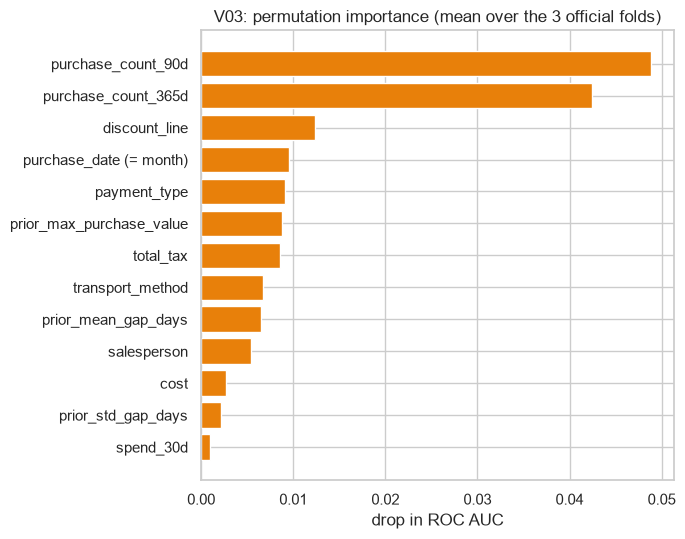

,fold 1,fold 2,fold 3,mean
purchase_count_90d,0.0426,0.0525,0.0516,0.0489
purchase_count_365d,0.0438,0.0360,0.0474,0.0424
discount_line,0.0173,0.0051,0.0147,0.0124
purchase_date (= month),-0.0017,0.0160,0.0143,0.0095
payment_type,0.0141,0.0107,0.0023,0.0090
prior_max_purchase_value,0.0123,0.0035,0.0105,0.0088
total_tax,-0.0030,0.0191,0.0095,0.0085
transport_method,0.0158,0.0066,-0.0022,0.0067
prior_mean_gap_days,0.0043,0.0089,0.0063,0.0065
salesperson,0.0055,0.0038,0.0070,0.0055


In [5]:
from sklearn.inspection import permutation_importance

# Permutation importance on each official fold: fit on the fold's train, shuffle one raw column of the
# validation block at a time and measure the drop in ROC AUC.
auc_drops = {}
for k, (tr, va) in enumerate(official_folds, start=1):
    fold_model = v03_pipeline().fit(X_full.iloc[tr], y.iloc[tr])
    result = permutation_importance(fold_model, X_full.iloc[va], y.iloc[va], scoring="roc_auc",
                                    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    auc_drops[f"fold {k}"] = pd.Series(result.importances_mean, index=X_full.columns)

auc_drops = (pd.DataFrame(auc_drops)
         .drop(index=["customer_id", "random_noise"])           # dropped by the pipeline anyway
         .rename(index={"purchase_date": "purchase_date (= month)"}))
auc_drops["mean"] = auc_drops.mean(axis=1)
top = auc_drops.sort_values("mean").query("mean > 0")

fig, ax = plt.subplots(figsize=(7, 0.35 * len(top) + 1))
ax.barh(top.index, top["mean"], color="#E8800A")
ax.set(title="V03: permutation importance (mean over the 3 official folds)", xlabel="drop in ROC AUC")
plt.tight_layout()
plt.show()
auc_drops.sort_values("mean", ascending=False).head(15).style.format("{:.4f}")